# Практическая работа № 4
## Очистка данных кибербезопасности: ошибки, дубликаты и пропуски

Решение использует приложенный `soc_events_dirty.csv`. Ячейки выполняются сверху вниз. Исходная таблица `df_raw` сохраняется без изменений. Ошибочные записи и технические повторы остаются в отдельных таблицах для аудита. Пропуск метки `is_attack` не заменяется значением 0.

## 0. Загрузка данных

Блокнот сначала ищет CSV в текущей папке, затем в папке практики. Если файл отсутствует, выполнение останавливается: расчёты по искусственным данным не отвечали бы заданию.

In [3]:
from pathlib import Path
import ipaddress

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

# Находим исходный файл, не изменяя его.
data_path = Path('soc_events_dirty.csv')
if not data_path.exists():
    data_path = Path(r'D:\University\Разработка програмных средств поиска и анализа киберугроз\Практика 4\soc_events_dirty.csv')
if not data_path.exists():
    raise FileNotFoundError('Не найден soc_events_dirty.csv')

# keep_default_na=False сохраняет текстовые маркеры пропусков для аудита.
df_raw = pd.read_csv(data_path, keep_default_na=False)
df_raw_snapshot = df_raw.copy(deep=True)
print('Файл:', data_path.resolve())
print('Размер исходной таблицы:', df_raw.shape)
display(df_raw.head())

Файл: D:\University\Разработка програмных средств поиска и анализа киберугроз\Практика 4\soc_events_dirty.csv
Размер исходной таблицы: (1284, 18)


,record_id,event_id,event_time,sensor_id,source_type,src_ip,dst_ip,dst_port,protocol,bytes_sent,duration_sec,failed_logins,country,cve_id,payload_hash,attack_type,is_attack,raw_log
0,REC-00001,EVT-00001,2026-07-14 08:00:35,ids-01,IDS,10.13.167.217,172.16.13.178,123,UDP,543.0,16.44,0.0,CN,CVE-2026-0442,sha256:0d4cc52bc59e,benign,0.0,Jul 14 08:00:35 ids-01 flow: src=10.13.167.217 dst=172.16.13.178 proto=UDP port=123 bytes=543
1,REC-00002,EVT-00002,2026-07-14 08:01:52,ids-01,IDS,23.79.92.118,172.16.3.129,161,UDP,1453.0,9.9,0.0,CN,CVE-2026-0442,sha256:20d3f78f8fdd,benign,0.0,Jul 14 08:01:52 ids-01 flow: src=23.79.92.118 dst=172.16.3.129 proto=UDP port=161 bytes=1453
2,REC-00003,EVT-00003,2026-07-14 08:02:18,ids-01,IDS,45.243.144.176,172.16.3.131,22,TCP,225.0,18.67,0.0,BR,CVE-2025-1021,sha256:6b56aee6a4d7,benign,0.0,Jul 14 08:02:18 host1 sshd[4387]: Accepted password for guest from 45.243.144.176 port 22
3,REC-00004,EVT-00004,2026-07-14 08:02:47,edr-02,EDR,91.2.122.16,172.16.23.31,443,TCP,314.0,5.7,0.0,DE,CVE-2026-0442,sha256:1f002e1d3aa3,benign,0.0,"Jul 14 08:02:47 web1 nginx: 91.2.122.16 ""GET /api/item/362 HTTP/1.1"" 404"
4,REC-00005,EVT-00005,2026-07-14 08:03:11,ids-02,IDS,10.15.123.40,172.16.13.46,0,ICMP,728.0,2.63,0.0,,CVE-2026-0442,,benign,,Jul 14 08:03:11 ids-02 flow: src=10.15.123.40 dst=172.16.13.46 proto=ICMP port=0 bytes=728


## Вспомогательные функции

In [5]:
def is_valid_ip(value):
    # Библиотека ipaddress проверяет все части IPv4 или IPv6 адреса.
    try:
        ipaddress.ip_address(str(value))
        return True
    except ValueError:
        return False


def extract_template(logs):
    # Меняющиеся детали журнала заменяем общими обозначениями.
    templates = logs.astype('string')
    templates = templates.str.replace(
        r'^[A-Za-z]{3}\s+\d{1,2}\s+\d{2}:\d{2}:\d{2}\s+\S+\s+',
        '', regex=True
    )
    templates = templates.str.replace(r'\b(?:\d{1,3}\.){3}\d{1,3}\b', '<IP>', regex=True)
    templates = templates.str.replace(r'\b\d+\b', '<NUM>', regex=True)
    templates = templates.str.replace(r'/[\w/.-]+', '<PATH>', regex=True)
    return templates.str.replace(r'\s+', ' ', regex=True).str.strip()

## Задание 1. Первичный аудит и скрытые пропуски

Сначала смотрим на данные без преобразований. `describe(include='all')` помогает заметить необычные значения даже в текстовых столбцах.

In [7]:
# Показываем размер, типы, общую сводку и точные дубликаты.
print('Размер:', df_raw.shape)
print('Типы столбцов:')
display(df_raw.dtypes.to_frame('Тип'))
print('Полных дубликатов:', int(df_raw.duplicated().sum()))
print('Явных пропусков:', int(df_raw.isna().sum().sum()))
display(df_raw.describe(include='all').T)

Размер: (1284, 18)
Типы столбцов:
Полных дубликатов: 32
Явных пропусков: 0


,Тип
record_id,str
event_id,str
event_time,str
sensor_id,str
source_type,str
src_ip,str
dst_ip,str
dst_port,int64
protocol,str
bytes_sent,float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
record_id,1284,1252,REC-00031,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_id,1284,1224,EVT-00020,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_time,1284,1185,not-a-date,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sensor_id,1284,6,ids-01,291,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_type,1284,3,IDS,543,NaN,NaN,NaN,NaN,NaN,NaN,NaN
src_ip,1284,1189,185.77.88.99,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dst_ip,1284,1094,172.16.10.25,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dst_port,1284.0,NaN,NaN,NaN,1721.722741,7150.532897,-1.0,53.0,161.0,500.0,99999.0
protocol,1284,6,TCP,871,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bytes_sent,1284.0,NaN,NaN,NaN,3535.236631,18362.531835,-861.0,559.0,1214.5,2641.0,352399.814513


In [8]:
# Ищем текстовые обозначения пропусков независимо от регистра и пробелов.
hidden_markers = {'', '-', 'n/a', 'null', 'unknown'}
df = df_raw.copy()
hidden_counts = {}

for column in df.columns:
    if pd.api.types.is_string_dtype(df[column]):
        normalized = df[column].astype('string').str.strip().str.lower()
        is_marker = normalized.isin(hidden_markers)
        hidden_counts[column] = int(is_marker.sum())
        df.loc[is_marker, column] = np.nan

hidden_report = pd.Series(hidden_counts, name='Скрытые маркеры')
hidden_report = hidden_report[hidden_report > 0].sort_values(ascending=False)
display(hidden_report.to_frame())
print('Всего распознано маркеров:', int(hidden_report.sum()))

# Превращаем текстовые числа в числа; ошибки преобразования станут NaN.
numeric_columns = ['dst_port', 'bytes_sent', 'duration_sec', 'failed_logins', 'is_attack']
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')

missing_after_markers = pd.DataFrame({
    'Количество': df.isna().sum(),
    'Доля': df.isna().mean()
})
display(missing_after_markers[missing_after_markers['Количество'] > 0].round(3))

Всего распознано маркеров: 1312


,Скрытые маркеры
cve_id,603
payload_hash,235
is_attack,221
country,107
duration_sec,88
failed_logins,58


,Количество,Доля
duration_sec,88,0.069
failed_logins,58,0.045
country,107,0.083
cve_id,603,0.470
payload_hash,235,0.183
is_attack,221,0.172


### Вывод по первичному аудиту

Исходная таблица содержит 1284 строки и 18 столбцов. До распознавания текстовых маркеров явных пропусков нет, но найдены 32 полных дубликата. Маркеры `''`, `'-'`, `N/A`, `null`, `unknown` обозначают 1312 пропусков; больше всего их в `cve_id` (603), `payload_hash` (235) и `is_attack` (221). Изменения сделаны в копии, поэтому исходные значения доступны для повторной проверки.

## Задание 2. Трёхуровневая валидация

Проверяем формат IP и времени, допустимые диапазоны, затем совместимость порта и протокола. Пропуск длительности на этом этапе допускается для последующей импутации; отрицательная длительность считается ошибкой.

In [11]:
# Нормализуем протокол: «tcp», «Tcp» и « TCP » становятся «TCP».
df['protocol'] = df['protocol'].astype('string').str.strip().str.upper()
df['event_time_parsed'] = pd.to_datetime(df['event_time'], errors='coerce')

# Отдельный флаг позволяет увидеть причину каждой проблемы.
df['src_ip_valid'] = df['src_ip'].apply(is_valid_ip)
df['dst_ip_valid'] = df['dst_ip'].apply(is_valid_ip)
df['time_valid'] = df['event_time_parsed'].notna()
df['port_valid'] = df['dst_port'].notna() & df['dst_port'].between(0, 65535)
df['bytes_valid'] = df['bytes_sent'].notna() & df['bytes_sent'].ge(0)
df['duration_valid'] = df['duration_sec'].isna() | df['duration_sec'].ge(0)
df['protocol_valid'] = df['protocol'].isin(['TCP', 'UDP', 'ICMP'])

# Список учебных сервисов дополнен портами 445 и 3389 из данного CSV.
# Он нужен для проверки ожидаемых пар, а не для вывода об атаке.
allowed_pairs = {
    0: {'ICMP'}, 22: {'TCP'}, 53: {'TCP', 'UDP'},
    80: {'TCP'}, 123: {'UDP'}, 161: {'UDP'},
    443: {'TCP'}, 445: {'TCP'}, 500: {'UDP'},
    3389: {'TCP'}, 8080: {'TCP'}
}

def check_port_protocol(row):
    # Если порт не входит в учебный список, пару отправляем на проверку.
    if pd.isna(row['dst_port']) or pd.isna(row['protocol']):
        return False
    port = int(row['dst_port'])
    return row['protocol'] in allowed_pairs.get(port, set())

df['port_protocol_valid'] = df.apply(check_port_protocol, axis=1)
validation_columns = [
    'src_ip_valid', 'dst_ip_valid', 'time_valid', 'port_valid',
    'bytes_valid', 'duration_valid', 'protocol_valid', 'port_protocol_valid'
]
display(df[validation_columns].sum().to_frame('Корректных строк'))

,Корректных строк
src_ip_valid,1269
dst_ip_valid,1284
time_valid,1279
port_valid,1272
bytes_valid,1274
duration_valid,1276
protocol_valid,1284
port_protocol_valid,1247


In [12]:
# Строка корректна, только если выполнены все проверки.
df['is_valid'] = df[validation_columns].all(axis=1)
error_names = {
    'src_ip_valid': 'invalid_src_ip',
    'dst_ip_valid': 'invalid_dst_ip',
    'time_valid': 'invalid_time',
    'port_valid': 'invalid_port',
    'bytes_valid': 'invalid_bytes',
    'duration_valid': 'invalid_duration',
    'protocol_valid': 'invalid_protocol',
    'port_protocol_valid': 'invalid_port_protocol_pair'
}

def collect_errors(row):
    # Одна строка может иметь несколько ошибок; записываем их все.
    errors = []
    for flag, explanation in error_names.items():
        if not row[flag]:
            errors.append(explanation)
    return '; '.join(errors)

df['error_reason'] = df.apply(collect_errors, axis=1)
df_valid = df[df['is_valid']].copy()
df_quarantine = df[~df['is_valid']].copy()

print('Корректных строк:', len(df_valid))
print('Строк в карантине:', len(df_quarantine))
display(df_quarantine[['record_id', 'event_id', 'src_ip', 'dst_ip',
                       'dst_port', 'protocol', 'bytes_sent', 'duration_sec',
                       'error_reason']].head(10))

Корректных строк: 1212
Строк в карантине: 72


,record_id,event_id,src_ip,dst_ip,dst_port,protocol,bytes_sent,duration_sec,error_reason
8,REC-00009,EVT-00009,10.8.55.191,172.16.21.27,443,UDP,136.0,-2.63,invalid_duration; invalid_port_protocol_pair
34,REC-00035,EVT-00035,10.6.33.204,172.16.11.208,80,TCP,-378.0,16.67,invalid_bytes
43,REC-00044,EVT-00044,10.10.154.14,172.16.17.103,445,UDP,490.0,10.07,invalid_port_protocol_pair
46,REC-00047,EVT-00047,10.1.15.1,172.16.5.54,443,TCP,-327.0,NaN,invalid_bytes
61,REC-00062,EVT-00062,10.6.235.180,172.16.5.61,22,TCP,1343.0,-13.38,invalid_duration
62,REC-00063,EVT-00063,10.10.71.243,172.16.11.101,-1,ICMP,1227.0,110.25,invalid_port; invalid_port_protocol_pair
64,REC-00065,EVT-00065,10.12.121.196,172.16.2.220,443,TCP,994.0,17.40,invalid_time
70,REC-00071,EVT-00071,10.12.193.133,172.16.9.118,80,TCP,-716.0,16.33,invalid_bytes
80,REC-00081,EVT-00081,999.999.999.999,172.16.5.182,500,UDP,1214.0,0.69,invalid_src_ip
83,REC-00084,EVT-00084,999.999.999.999,172.16.18.144,123,UDP,1545.0,27.12,invalid_src_ip


### Вывод по валидации

Из 1284 исходных строк 1212 прошли проверки, а 72 помещены в карантин с указанием причин. Обнаружены ошибочные IP-адреса и время, отрицательные значения, порты вне диапазона и несоответствия учебному перечню пар «порт — протокол»; одна строка может иметь несколько причин. Карантин сохраняет записи для ручной проверки SOC. Необычную, но технически допустимую активность нельзя автоматически считать ошибкой данных или удалять.

## Задание 3. Технические и семантические дубликаты

Точные копии строк и повтор одного `event_id` считаем техническими повторами для основной таблицы. Удалённые экземпляры оставляем в `df_removed_duplicates`, поскольку разные датчики могут сообщать об одном событии и их идентификаторы нужны для аудита.

In [15]:
# Сначала сохраняем точные копии, затем удаляем их из рабочей таблицы.
exact_duplicate_rows = df_valid[df_valid.duplicated(keep='first')].copy()
exact_duplicate_rows['duplicate_reason'] = 'full_row'
df_without_exact = df_valid.drop_duplicates().copy()

# Один event_id может прийти от двух датчиков. Вторую запись сохраняем
# в аудите, а в основной таблице оставляем первое наблюдение.
event_duplicate_rows = df_without_exact[
    df_without_exact.duplicated(subset='event_id', keep='first')
].copy()
event_duplicate_rows['duplicate_reason'] = 'same_event_id'
df_dedup = df_without_exact.drop_duplicates(subset='event_id', keep='first').copy()

df_removed_duplicates = pd.concat(
    [exact_duplicate_rows, event_duplicate_rows], ignore_index=True
)
removed_exact = len(exact_duplicate_rows)
removed_ids = len(event_duplicate_rows)

print('Удалено полных копий:', removed_exact)
print('Удалено повторов event_id из основной таблицы:', removed_ids)
print('Размер основной таблицы:', df_dedup.shape)
display(df_removed_duplicates[['record_id', 'event_id', 'sensor_id',
                               'duplicate_reason']].head(10))

Удалено полных копий: 31
Удалено повторов event_id из основной таблицы: 27
Размер основной таблицы: (1154, 29)


,record_id,event_id,sensor_id,duplicate_reason
0,REC-00318,EVT-00318,edr-01,full_row
1,REC-01026,EVT-01026,ids-02,full_row
2,REC-00943,EVT-00943,edr-02,full_row
3,REC-00049,EVT-00049,edr-01,full_row
4,REC-00934,EVT-00934,ids-02,full_row
5,REC-00416,EVT-00416,edr-02,full_row
6,REC-01046,EVT-01046,ids-01,full_row
7,REC-00995,EVT-00995,ids-02,full_row
8,REC-00951,EVT-00951,fw-01,full_row
9,REC-01105,EVT-01105,ids-02,full_row


In [16]:
# Серия брутфорса состоит из разных событий. Сохраняем строки и отдельно
# получаем сводку по источнику, назначению, порту и минуте.
bruteforce = df_dedup[df_dedup['attack_type'] == 'bruteforce'].copy()
bruteforce['minute_window'] = bruteforce['event_time_parsed'].dt.floor('min')

bruteforce_summary = bruteforce.groupby(
    ['src_ip', 'dst_ip', 'dst_port', 'minute_window']
).agg(
    event_count=('event_id', 'count'),
    total_bytes=('bytes_sent', 'sum'),
    first_seen=('event_time_parsed', 'min'),
    last_seen=('event_time_parsed', 'max')
).reset_index()
bruteforce_summary['duration_sec'] = (
    bruteforce_summary['last_seen'] - bruteforce_summary['first_seen']
).dt.total_seconds()

print('Событий брутфорса в основной таблице:', len(bruteforce))
print('Минутных групп:', len(bruteforce_summary))
display(bruteforce_summary.sort_values('event_count', ascending=False).head(10))

Событий брутфорса в основной таблице: 74
Минутных групп: 52


,src_ip,dst_ip,dst_port,minute_window,event_count,total_bytes,first_seen,last_seen,duration_sec
42,185.77.88.99,172.16.10.25,22,2026-07-14 15:41:00,12,5760.0,2026-07-14 15:41:00,2026-07-14 15:41:55,55.0
41,185.77.88.99,172.16.10.25,22,2026-07-14 15:40:00,12,5760.0,2026-07-14 15:40:00,2026-07-14 15:40:55,55.0
0,10.0.157.88,172.16.13.16,22,2026-07-14 12:52:00,1,3495.0,2026-07-14 12:52:21,2026-07-14 12:52:21,0.0
1,10.1.161.4,172.16.3.59,22,2026-07-14 12:16:00,1,524.0,2026-07-14 12:16:14,2026-07-14 12:16:14,0.0
4,10.10.102.202,172.16.21.219,22,2026-07-14 13:12:00,1,1038.0,2026-07-14 13:12:31,2026-07-14 13:12:31,0.0
5,10.10.241.232,172.16.15.23,22,2026-07-14 08:09:00,1,673.0,2026-07-14 08:09:20,2026-07-14 08:09:20,0.0
6,10.10.59.229,172.16.9.206,22,2026-07-14 08:30:00,1,1210.0,2026-07-14 08:30:29,2026-07-14 08:30:29,0.0
7,10.10.77.144,172.16.16.171,22,2026-07-14 15:39:00,1,1020.0,2026-07-14 15:39:39,2026-07-14 15:39:39,0.0
8,10.11.220.180,172.16.23.41,22,2026-07-14 12:47:00,1,1240.0,2026-07-14 12:47:25,2026-07-14 12:47:25,0.0
9,10.11.236.48,172.16.18.51,22,2026-07-14 10:57:00,1,2514.0,2026-07-14 10:57:25,2026-07-14 10:57:25,0.0


In [17]:
# Точный повтор текста журнала не обязательно означает повтор всего события.
exact_text_duplicate_rows = int(df_dedup.duplicated('raw_log', keep=False).sum())
unique_logs = df_dedup.drop_duplicates(subset='raw_log').copy()
unique_logs['template'] = extract_template(unique_logs['raw_log'])
top_templates = unique_logs['template'].value_counts().head(5)

print('Строк, участвующих в точных повторах raw_log:', exact_text_duplicate_rows)
print('Уникальных текстов:', len(unique_logs))
display(top_templates.to_frame('Количество'))

Строк, участвующих в точных повторах raw_log: 24
Уникальных текстов: 1142


,Количество
template,
"nginx: <IP> ""GET <PATH><NUM> HTTP/<NUM>.<NUM>"" <NUM>",381
flow: src=<IP> dst=<IP> proto=UDP port=<NUM> bytes=<NUM>,244
flow: src=<IP> dst=<IP> proto=TCP port=<NUM> bytes=<NUM>,238
flow: src=<IP> dst=<IP> proto=ICMP port=<NUM> bytes=<NUM>,96
sshd[<NUM>]: Failed password for root from <IP> port <NUM>,42


### Дополнительно: нечёткие повторы текстов

TF-IDF сравнивает фрагменты строк, а косинусное сходство оценивает их похожесть. Высокое сходство означает повод для проверки: похожие строки могут быть разными попытками атаки.

In [ ]:
# Сравниваем все уникальные тексты, чтобы не пропустить серию в конце файла.

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
logs_for_similarity = unique_logs['raw_log'].dropna().reset_index(drop=True)
vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5))
text_vectors = vectorizer.fit_transform(logs_for_similarity)
similarity = cosine_similarity(text_vectors)
similar_pairs = []
for first in range(len(logs_for_similarity)):
    for second in range(first + 1, len(logs_for_similarity)):
        if similarity[first, second] >= 0.70:
            similar_pairs.append({
                'Первая строка': first,
                'Вторая строка': second,
                'Сходство': similarity[first, second],
                'Текст 1': logs_for_similarity[first][:90],
                'Текст 2': logs_for_similarity[second][:90]
            })
similar_pairs_table = pd.DataFrame(similar_pairs)
if not similar_pairs_table.empty:
    similar_pairs_table = similar_pairs_table.sort_values(
        'Сходство', ascending=False
    ).head(10)
print('Кандидатов со сходством не ниже 0,70:', len(similar_pairs))
display(similar_pairs_table)

Кандидатов со сходством не ниже 0,70: 59


,Первая строка,Вторая строка,Сходство,Текст 1,Текст 2
34,1122,1123,0.749532,Jul 14 15:40:20 host1 sshd[7004]: Failed password for root from 185.77.88.99 port 22,Jul 14 15:40:25 host1 sshd[7005]: Failed password for root from 185.77.88.99 port 22
48,1126,1127,0.743681,Jul 14 15:40:40 host1 sshd[7008]: Failed password for root from 185.77.88.99 port 22,Jul 14 15:40:45 host1 sshd[7009]: Failed password for root from 185.77.88.99 port 22
17,1120,1121,0.742129,Jul 14 15:40:10 host1 sshd[7002]: Failed password for root from 185.77.88.99 port 22,Jul 14 15:40:15 host1 sshd[7003]: Failed password for root from 185.77.88.99 port 22
54,1138,1139,0.740945,Jul 14 15:40:100 host1 sshd[7020]: Failed password for root from 185.77.88.99 port 22,Jul 14 15:40:105 host1 sshd[7021]: Failed password for root from 185.77.88.99 port 22
43,1124,1125,0.740226,Jul 14 15:40:30 host1 sshd[7006]: Failed password for root from 185.77.88.99 port 22,Jul 14 15:40:35 host1 sshd[7007]: Failed password for root from 185.77.88.99 port 22
0,1118,1119,0.739896,Jul 14 15:40:00 host1 sshd[7000]: Failed password for root from 185.77.88.99 port 22,Jul 14 15:40:05 host1 sshd[7001]: Failed password for root from 185.77.88.99 port 22
49,1128,1129,0.739243,Jul 14 15:40:50 host1 sshd[7010]: Failed password for root from 185.77.88.99 port 22,Jul 14 15:40:55 host1 sshd[7011]: Failed password for root from 185.77.88.99 port 22
58,1140,1141,0.733280,Jul 14 15:40:110 host1 sshd[7022]: Failed password for root from 185.77.88.99 port 22,Jul 14 15:40:115 host1 sshd[7023]: Failed password for root from 185.77.88.99 port 22
24,1120,1138,0.723513,Jul 14 15:40:10 host1 sshd[7002]: Failed password for root from 185.77.88.99 port 22,Jul 14 15:40:100 host1 sshd[7020]: Failed password for root from 185.77.88.99 port 22
25,1120,1139,0.722716,Jul 14 15:40:10 host1 sshd[7002]: Failed password for root from 185.77.88.99 port 22,Jul 14 15:40:105 host1 sshd[7021]: Failed password for root from 185.77.88.99 port 22


### Вывод по повторам

Из корректных строк удалены 31 полная копия и 27 повторов `event_id`; их экземпляры сохранены в `df_removed_duplicates` вместе с датчиками и причиной исключения. В рабочей таблице осталось 1154 события. Среди них 74 события брутфорса: для источника `185.77.88.99` и назначения `172.16.10.25:22` обнаружено по 12 событий в каждом из двух соседних минутных окон. Эти события сохранены, а минутная сводка служит дополнительным признаком интенсивности. Среди журналов 24 строки участвуют в точных повторах текста; TF-IDF дополнительно нашёл 59 пар с косинусным сходством не ниже 0,70. Похожесть сообщений не служит основанием удалять разные события. Некоторые временные фрагменты в `raw_log` выглядят некорректно, поэтому минутная агрегация использует проверенный `event_time`.

## Задание 4. Диагностика механизмов пропусков

,Количество,Доля
cve_id,549,0.476
payload_hash,212,0.184
is_attack,200,0.173
country,99,0.086
duration_sec,79,0.068
failed_logins,49,0.042


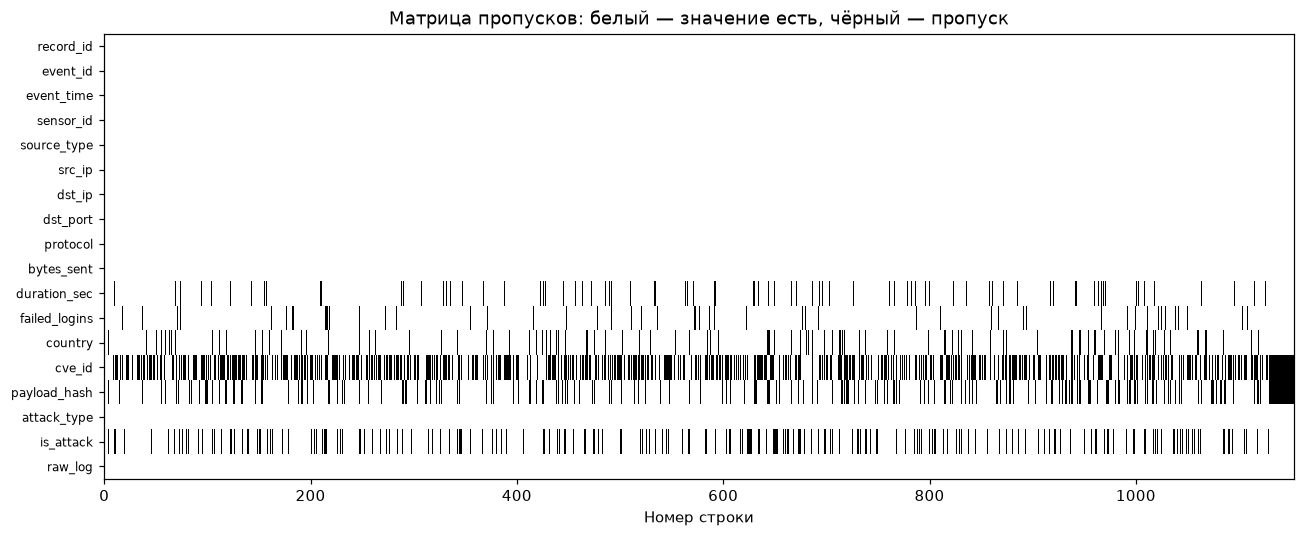

In [22]:
# Отчёт строим после валидации и дедупликации, до заполнения.
missing_report = pd.DataFrame({
    'Количество': df_dedup.isna().sum(),
    'Доля': df_dedup.isna().mean()
}).sort_values('Количество', ascending=False)
display(missing_report[missing_report['Количество'] > 0].round(3))

# По вертикали расположены признаки, по горизонтали — строки.
original_columns = list(df_raw.columns)
fig, ax = plt.subplots(figsize=(12, 5))
ax.imshow(df_dedup[original_columns].isna().T,
          aspect='auto', interpolation='nearest', cmap='gray_r')
ax.set_yticks(range(len(original_columns)))
ax.set_yticklabels(original_columns, fontsize=8)
ax.set_xlabel('Номер строки')
ax.set_title('Матрица пропусков: белый — значение есть, чёрный — пропуск')
plt.tight_layout()
plt.show()

In [23]:
# Индикатор True означает, что исходное значение было пропущено.
missing_cols = [
    'duration_sec', 'country', 'cve_id',
    'failed_logins', 'payload_hash', 'is_attack'
]
df_missing = df_dedup.copy()
for column in missing_cols:
    df_missing[column + '_missing'] = df_missing[column].isna()

country_by_protocol = df_missing.groupby('protocol')['country_missing'].mean()
cve_by_source = df_missing.groupby('source_type')['cve_id_missing'].mean()
failed_by_attack = df_missing.dropna(subset=['is_attack']).groupby(
    'is_attack'
)['failed_logins_missing'].mean()
payload_by_protocol = df_missing.groupby('protocol')['payload_hash_missing'].mean()
label_by_type = df_missing.groupby('attack_type')['is_attack_missing'].mean()
duration_by_source = df_missing.groupby('source_type')['duration_sec_missing'].mean()

print('Доля пропусков country по protocol:')
display(country_by_protocol.to_frame('Доля').round(3))
print('Доля пропусков cve_id по source_type:')
display(cve_by_source.to_frame('Доля').round(3))
print('Доля пропусков failed_logins по доступной is_attack:')
display(failed_by_attack.to_frame('Доля').round(3))
print('Доля пропусков payload_hash по protocol:')
display(payload_by_protocol.to_frame('Доля').round(3))
print('Доля пропусков is_attack по attack_type:')
display(label_by_type.to_frame('Доля').round(3))
print('Доля пропусков duration_sec по source_type:')
display(duration_by_source.to_frame('Доля').round(3))

Доля пропусков country по protocol:
Доля пропусков cve_id по source_type:
Доля пропусков failed_logins по доступной is_attack:
Доля пропусков payload_hash по protocol:
Доля пропусков is_attack по attack_type:
Доля пропусков duration_sec по source_type:


,Доля
protocol,
ICMP,0.531
TCP,0.044
UDP,0.049


,Доля
source_type,
EDR,0.610
Firewall,0.873
IDS,0.134


,Доля
is_attack,
0.0,0.014
1.0,0.231


,Доля
protocol,
ICMP,1.000
TCP,0.143
UDP,0.000


,Доля
attack_type,
benign,0.195
bruteforce,0.014
exfiltration,0.150
malware,0.000
scan,0.000


,Доля
source_type,
EDR,0.055
Firewall,0.065
IDS,0.082


### Вывод о механизмах пропусков

После валидации и дедупликации пропущены 549 значений `cve_id` (47,6%), 212 `payload_hash` (18,4%), 200 `is_attack` (17,3%), 99 `country` (8,6%), 79 `duration_sec` (6,8%) и 49 `failed_logins` (4,2%). Пропуск `country` особенно часто встречается при ICMP (53,1% против 4,4% у TCP), `cve_id` — у Firewall (87,3%), `payload_hash` — у ICMP (100%). Среди доступных меток доля пропусков `failed_logins` равна 23,1% для атак и 1,4% для неатакующих событий. Это поддерживает гипотезу MAR для этих признаков. Для длительности MCAR не исключён, но не доказан. Пропуски `is_attack` различаются по `attack_type`; их нельзя автоматически объявить MNAR или заполнять по видимому типу атаки, поскольку процесс разметки неизвестен.

In [25]:
# Механизм — гипотеза, а не доказанное свойство данных.
mechanism_table = pd.DataFrame({
    'Признак': missing_cols,
    'Рабочая гипотеза': [
        'MCAR не исключён', 'MAR', 'MAR', 'MAR', 'MAR', 'MAR; риск MNAR'
    ],
    'Основание': [
        'Проверяем групповые доли; отсутствие различий не доказывает MCAR.',
        'Доля зависит от наблюдаемого protocol.',
        'Доля зависит от наблюдаемого source_type.',
        'Доля различается по доступной метке is_attack.',
        'Доля зависит от protocol и способа сбора.',
        'Доля связана с attack_type; процесс разметки может добавлять MNAR.'
    ],
    'Действие': [
        'Медиана по protocol и индикатор.',
        'Категория unknown и индикатор.',
        'Категория not_reported и индикатор.',
        'Значение -1 и индикатор; не считать -1 числом попыток.',
        'Категория not_collected и индикатор.',
        'Не заполнять; передать на проверку разметки.'
    ]
})
display(mechanism_table)

,Признак,Рабочая гипотеза,Основание,Действие
0,duration_sec,MCAR не исключён,Проверяем групповые доли; отсутствие различий не доказывает MCAR.,Медиана по protocol и индикатор.
1,country,MAR,Доля зависит от наблюдаемого protocol.,Категория unknown и индикатор.
2,cve_id,MAR,Доля зависит от наблюдаемого source_type.,Категория not_reported и индикатор.
3,failed_logins,MAR,Доля различается по доступной метке is_attack.,Значение -1 и индикатор; не считать -1 числом попыток.
4,payload_hash,MAR,Доля зависит от protocol и способа сбора.,Категория not_collected и индикатор.
5,is_attack,MAR; риск MNAR,Доля связана с attack_type; процесс разметки может добавлять MNAR.,Не заполнять; передать на проверку разметки.


## Задание 5. Импутация, контроль качества и записка SOC

Индикаторы создаются до заполнения. Медиана применяется к длительности, а пропуск числа неудачных входов оставляем узнаваемым через индикатор и служебное значение −1. Это значение не означает реальное число попыток. Для категорий используем явные обозначения отсутствия данных. `is_attack` остаётся без искусственной метки.

In [27]:
df_clean = df_dedup.copy()

# Сохраняем сведения о том, где были пропуски изначально.
for column in missing_cols:
    df_clean[column + '_missing'] = df_clean[column].isna()
unlabeled_before = int(df_clean['is_attack'].isna().sum())

# Для длительности сначала берём медиану протокола, затем общую медиану.
duration_by_protocol = df_clean.groupby('protocol')['duration_sec'].transform('median')
df_clean['duration_sec'] = df_clean['duration_sec'].fillna(duration_by_protocol)
df_clean['duration_sec'] = df_clean['duration_sec'].fillna(df_clean['duration_sec'].median())

# -1 — специальный код пропуска, а не наблюдаемое число неудачных входов.
df_clean['failed_logins'] = df_clean['failed_logins'].fillna(-1)
df_clean['country'] = df_clean['country'].fillna('unknown')
df_clean['cve_id'] = df_clean['cve_id'].fillna('not_reported')
df_clean['payload_hash'] = df_clean['payload_hash'].fillna('not_collected')

# Целевую метку не угадываем по attack_type и не приравниваем к 0.
print('Пропуски после заполнения:')
display(df_clean[missing_cols].isna().sum().to_frame('Количество'))

Пропуски после заполнения:


,Количество
duration_sec,0
country,0
cve_id,0
failed_logins,0
payload_hash,0
is_attack,200


In [28]:
# Проверяем сохранность исходника и учёт каждой исключённой строки.
assert df_raw.equals(df_raw_snapshot)
assert len(df_raw) == len(df_quarantine) + len(df_removed_duplicates) + len(df_clean)
assert df_quarantine['is_valid'].eq(False).all()
assert df_clean['is_valid'].all()
assert df_clean['event_id'].is_unique
assert df_clean['record_id'].is_unique
assert not df_clean.duplicated().any()
assert df_clean['bytes_sent'].ge(0).all()
assert df_clean['duration_sec'].ge(0).all()
assert int(df_clean['is_attack'].isna().sum()) == unlabeled_before
assert df_clean.loc[df_clean['failed_logins_missing'], 'failed_logins'].eq(-1).all()
assert not df_clean[['duration_sec', 'country', 'cve_id',
                     'failed_logins', 'payload_hash']].isna().any().any()

cleaning_log = pd.DataFrame({
    'Этап': [
        'Исходные строки', 'Распознано скрытых маркеров',
        'Строки в карантине', 'Удалено полных копий',
        'Удалено повторов event_id', 'Итоговые строки',
        'Неразмеченные is_attack сохранены'
    ],
    'Количество': [
        len(df_raw), int(hidden_report.sum()), len(df_quarantine),
        removed_exact, removed_ids, len(df_clean), unlabeled_before
    ]
})
display(cleaning_log)

,Этап,Количество
0,Исходные строки,1284
1,Распознано скрытых маркеров,1312
2,Строки в карантине,72
3,Удалено полных копий,31
4,Удалено повторов event_id,27
5,Итоговые строки,1154
6,Неразмеченные is_attack сохранены,200


### Записка для SOC

Исходный набор содержит 1284 строки и 18 столбцов; распознано 1312 скрытых маркеров пропусков. По итогам валидации 72 записи помещены в карантин с сохранением идентификаторов и причин ошибок. Из корректных записей 31 полная копия и 27 повторов `event_id` исключены из основной таблицы, но сохранены отдельно для аудита; серия брутфорса не удалена и агрегирована по минутам. Пропуски `country`, `cve_id`, `payload_hash` и `failed_logins` зависят от наблюдаемых групп, поэтому их простое удаление могло бы исказить данные. Итоговая таблица содержит 1154 строки; 200 событий без метки `is_attack` оставлены неразмеченными и требуют проверки перед обучением модели. SOC следует отдельно просматривать карантин и исключённые записи разных датчиков, а также отслеживать доли пропусков и качество разметки во времени.